# ML Assignment 2 - QSAR Biodegradation

I used the UCI QSAR Biodegradation dataset to train and compare five classification models. All models are evaluated on the same 20% test split (`random_state=42`, stratified by target). The positive class is `RB` (ready biodegradable).

Dataset: [UCI QSAR Biodegradation](https://archive.ics.uci.edu/dataset/254/qsar%2Bbiodegradation).

## 1. Imports

In [3]:
import sys
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)
print('numpy:', np.__version__)
print('joblib:', joblib.__version__)

Python: 3.12.7
pandas: 2.2.3
scikit-learn: 1.9.1
numpy: 2.5.4
joblib: 1.4.2


## 2. Read the dataset

The file is semicolon-separated and does not contain a header. If downloading is blocked, upload `biodeg.csv` to the notebook folder.

In [5]:
possible_paths = [
    Path('biodeg.csv'),
    Path('data/biodeg.csv'),
    Path('../data/biodeg.csv'),
]
raw_path = next((p for p in possible_paths if p.is_file()), None)

if raw_path is None:
    dataset_url = 'https://archive.ics.uci.edu/static/public/254/qsar%2Bbiodegradation.zip'
    try:
        with urlopen(dataset_url, timeout=30) as response:
            zipped_bytes = response.read()
        with ZipFile(BytesIO(zipped_bytes)) as archive:
            filename = next(
                name for name in archive.namelist()
                if name.rsplit('/', 1)[-1] == 'biodeg.csv'
            )
            raw_path = Path('biodeg.csv')
            raw_path.write_bytes(archive.read(filename))
        print('Downloaded original dataset to:', raw_path)
    except Exception as exc:
        raise RuntimeError(
            'Could not download the dataset. Download from the UCI page, '
            'extract biodeg.csv, upload it beside this notebook, and rerun.'
        ) from exc
else:
    print('Using local data file:', raw_path)

raw = pd.read_csv(raw_path, sep=';', header=None, skipinitialspace=True)
print('Raw shape (rows, all columns):', raw.shape)
display(raw.head(3))

Using local data file: biodeg.csv
Raw shape (rows, all columns): (1055, 42)


,0,1,2,3,4,5,6,7,8,9,...,32,33,34,35,36,37,38,39,40,41
0,3.919,2.6909,0,0,0,0,0,31.4,2,0,...,0,0,0,2.949,1.591,0,7.253,0,0,RB
1,4.170,2.1144,0,0,0,0,0,30.8,1,1,...,0,0,0,3.315,1.967,0,7.257,0,0,RB
2,3.932,3.2512,0,0,0,0,0,26.7,2,4,...,0,0,1,3.076,2.417,0,7.601,0,0,RB


## 3. Data checks

In [7]:
assert raw.shape[1] == 42, f'Expected 42 columns, found {raw.shape[1]}'

feature_columns = [f'feature_{i:02d}' for i in range(1, 42)]
df = raw.copy()
df.columns = feature_columns + ['target']

df['target'] = df['target'].astype('string').str.strip()
for name in feature_columns:
    df[name] = pd.to_numeric(df[name], errors='raise')

assert set(df['target'].dropna().unique()) == {'NRB', 'RB'}, 'Unexpected class labels'
assert len(df) >= 500 and len(feature_columns) >= 12, 'Assignment size conditions not met'
assert not df.isna().any().any(), 'Found missing values; investigate before modeling'

print('Rows:', len(df))
print('Input features:', len(feature_columns))
print('Missing cells:', int(df.isna().sum().sum()))
print('Identical complete rows:', int(df.duplicated().sum()))
print('Identical feature rows:', int(df.duplicated(subset=feature_columns).sum()))
print('\nTarget counts:')
display(df['target'].value_counts().rename_axis('class').to_frame('records'))

display(df[feature_columns].describe().T.head(8))

Rows: 1055
Input features: 41
Missing cells: 0
Identical complete rows: 3
Identical feature rows: 3

Target counts:


,records
class,
NRB,699
RB,356


,count,mean,std,min,25%,50%,75%,max
feature_01,1055.0,4.782644,0.546916,2.0000,4.48100,4.8280,5.12500,6.4960
feature_02,1055.0,3.069508,0.831308,0.8039,2.50275,3.0463,3.43765,9.1775
feature_03,1055.0,0.716588,1.462452,0.0000,0.00000,0.0000,1.00000,12.0000
feature_04,1055.0,0.042654,0.256010,0.0000,0.00000,0.0000,0.00000,3.0000
feature_05,1055.0,0.980095,2.332955,0.0000,0.00000,0.0000,1.00000,36.0000
feature_06,1055.0,0.290047,1.073771,0.0000,0.00000,0.0000,0.00000,13.0000
feature_07,1055.0,1.646445,2.224822,0.0000,0.00000,1.0000,3.00000,18.0000
feature_08,1055.0,37.055640,9.144466,0.0000,30.45000,37.5000,43.40000,60.7000


### Class distribution

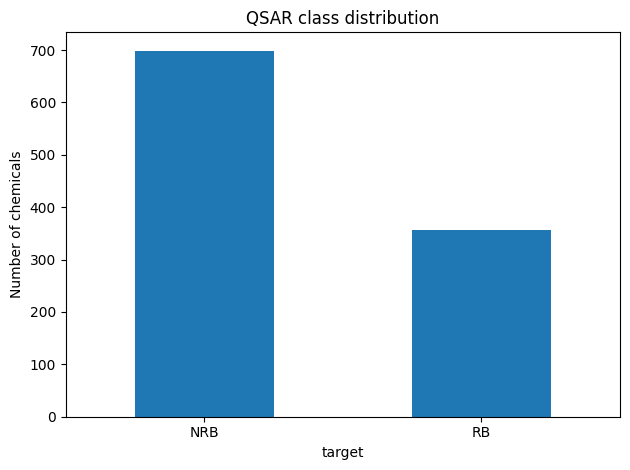

Majority-class-only guess: NRB; accuracy: 0.663


In [9]:
class_counts = df['target'].value_counts()
class_counts.plot(kind='bar', title='QSAR class distribution', ylabel='Number of chemicals', rot=0)
plt.tight_layout()
plt.show()

majority_class = class_counts.idxmax()
majority_accuracy = class_counts.max() / len(df)
print(f'Majority-class-only guess: {majority_class}; accuracy: {majority_accuracy:.3f}')

## 4. Train/test split

80% training data and 20% test data, stratified by target.

In [11]:
X = df[feature_columns]
y = df['target'].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print('Training records:', len(X_train))
print('Test records:', len(X_test))
print('Train class share (%)')
print((y_train.value_counts(normalize=True) * 100).round(1))
print('Test class share (%)')
print((y_test.value_counts(normalize=True) * 100).round(1))

train_signatures = set(map(tuple, X_train.to_numpy()))
test_signatures = set(map(tuple, X_test.to_numpy()))
overlap_count = len(train_signatures.intersection(test_signatures))
print('Unique exact feature rows shared across train and test:', overlap_count)
if overlap_count:
    print('WARNING: Inspect duplicate features and reconsider the split before final reporting.')

Training records: 844
Test records: 211
Train class share (%)
target
NRB    66.2
RB     33.8
Name: proportion, dtype: float64
Test class share (%)
target
NRB    66.4
RB     33.6
Name: proportion, dtype: float64
Unique exact feature rows shared across train and test: 0


## 5. Logistic Regression

In [13]:
logistic_model = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42)),
])

logistic_model.fit(X_train, y_train)
print('Pipeline trained on', len(X_train), 'training rows.')
print('Target class order:', logistic_model.classes_.tolist())

Pipeline trained on 844 training rows.
Target class order: ['NRB', 'RB']


## 6. Evaluation

For precision, recall and F1 the positive class is `RB`. AUC uses predicted probabilities.

In [15]:
positive_label = 'RB'
y_pred = logistic_model.predict(X_test)
rb_column = list(logistic_model.classes_).index(positive_label)
rb_probability = logistic_model.predict_proba(X_test)[:, rb_column]

metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'AUC': roc_auc_score((y_test == positive_label).astype(int), rb_probability),
    'Precision': precision_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
    'Recall': recall_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
    'F1': f1_score(y_test, y_pred, pos_label=positive_label, zero_division=0),
    'MCC': matthews_corrcoef(y_test, y_pred),
}

baseline_table = pd.DataFrame([{'Model': 'Logistic Regression', **metrics}])
display(baseline_table.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8626,0.9136,0.8,0.7887,0.7943,0.6912


## 7. Confusion matrix

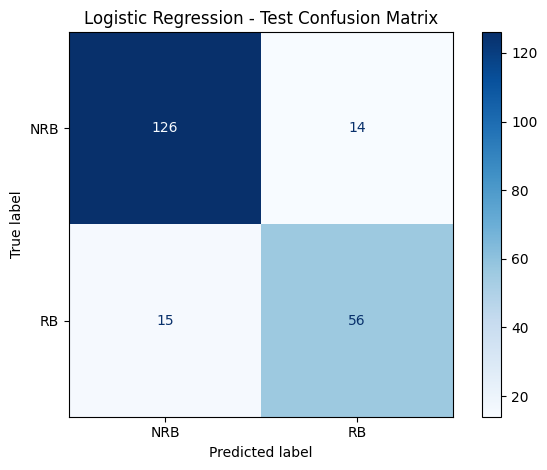

In [17]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=['NRB', 'RB'],
    display_labels=['NRB', 'RB'],
    cmap='Blues',
    values_format='d',
)
plt.title('Logistic Regression - Test Confusion Matrix')
plt.tight_layout()
plt.show()

## 8. Export the baseline model and test set

In [19]:
output_root = Path.cwd()
model_dir = output_root / 'model'
model_dir.mkdir(parents=True, exist_ok=True)

saved_test_data = X_test.copy()
saved_test_data['target'] = y_test
saved_test_data.to_csv(output_root / 'test_data.csv', index=False)

joblib.dump(logistic_model, model_dir / 'logistic_regression.joblib')
baseline_table.to_csv(output_root / 'baseline_metrics.csv', index=False)

print('Saved:', (output_root / 'test_data.csv').resolve())
print('Saved:', (model_dir / 'logistic_regression.joblib').resolve())
print('Saved:', (output_root / 'baseline_metrics.csv').resolve())
print('Test CSV shape:', pd.read_csv(output_root / 'test_data.csv').shape)

Saved: /home/s2026aj05843/workspace/ML Assignment 2/test_data.csv
Saved: /home/s2026aj05843/workspace/ML Assignment 2/model/logistic_regression.joblib
Saved: /home/s2026aj05843/workspace/ML Assignment 2/baseline_metrics.csv
Test CSV shape: (211, 42)


## 9. Other classification models

Decision Tree and Gaussian Naive Bayes use the original numeric features. KNN and SVM use scaling inside their pipelines. The test data is never used to fit the preprocessing or classifiers.

In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report

models = {
    'Logistic Regression': logistic_model,
    'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=5, random_state=42),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', KNeighborsClassifier(n_neighbors=7))
    ]),
    'Naive Bayes': GaussianNB(),
    'Support Vector Machine': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', SVC(kernel='rbf', probability=True, random_state=42))
    ]),
}

for name, model in models.items():
    if name != 'Logistic Regression':
        model.fit(X_train, y_train)
    print(name, '- ready')

Logistic Regression - ready
Decision Tree - ready
KNN - ready
Naive Bayes - ready
Support Vector Machine - ready


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 10. Model comparison

AUC is calculated from the probability assigned to `RB`. Precision, Recall, and F1 also use `RB` as the positive class.

In [23]:
def evaluate_model(model, X_test, y_test, positive='RB'):
    predictions = model.predict(X_test)
    class_names = list(model.classes_)
    rb_index = class_names.index(positive)
    probabilities = model.predict_proba(X_test)[:, rb_index]
    return {
        'Accuracy': accuracy_score(y_test, predictions),
        'AUC': roc_auc_score((y_test == positive).astype(int), probabilities),
        'Precision': precision_score(y_test, predictions, pos_label=positive, zero_division=0),
        'Recall': recall_score(y_test, predictions, pos_label=positive, zero_division=0),
        'F1': f1_score(y_test, predictions, pos_label=positive, zero_division=0),
        'MCC': matthews_corrcoef(y_test, predictions),
    }

comparison = pd.DataFrame([
    {'Model': name, **evaluate_model(model, X_test, y_test)}
    for name, model in models.items()
])
display(comparison.round(4))

# F1 is the primary ranking metric, with MCC and AUC as tie-breakers.
ranked = comparison.sort_values(['F1', 'MCC', 'AUC'], ascending=False)
winner = ranked.iloc[0]['Model']
print('Highest test F1:', winner)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8626,0.9136,0.8000,0.7887,0.7943,0.6912
1,Decision Tree,0.8152,0.8656,0.7162,0.7465,0.7310,0.5906
2,KNN,0.8389,0.8971,0.7403,0.8028,0.7703,0.6478
3,Naive Bayes,0.6967,0.8650,0.5276,0.9437,0.6768,0.4972
4,Support Vector Machine,0.8483,0.9189,0.7910,0.7465,0.7681,0.6562


Highest test F1: Logistic Regression


## 11. Confusion matrices

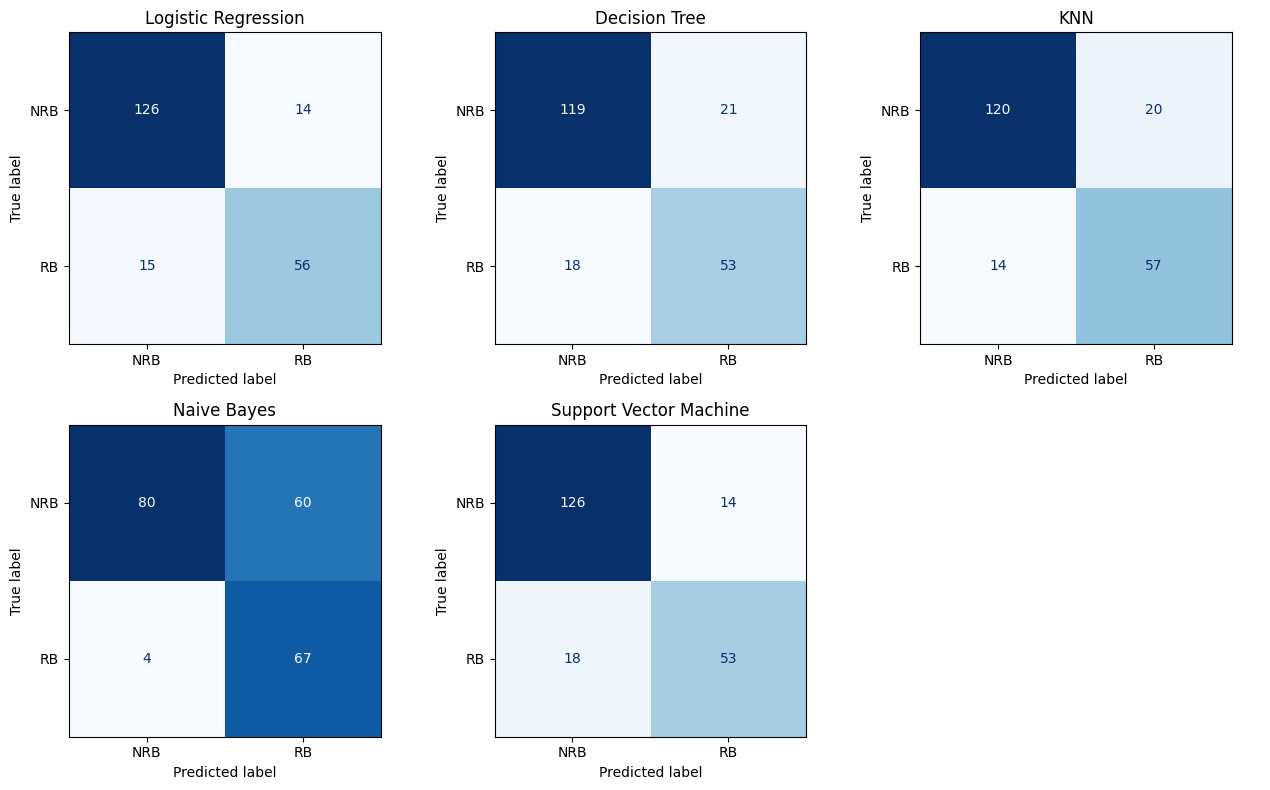

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, model) in zip(axes.flat, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, model.predict(X_test),
        labels=['NRB', 'RB'], display_labels=['NRB', 'RB'],
        ax=ax, cmap='Blues', values_format='d', colorbar=False
    )
    ax.set_title(name)
for ax in axes.flat[len(models):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 12. Results and observations

These comments are generated using the test-set scores and predicted classifications, rather than estimated figures. Model rankings depend on the metric chosen.

In [27]:
from IPython.display import Markdown, display

notes = []
for name, model in models.items():
    row = comparison.loc[comparison['Model'] == name].iloc[0]
    tn, fp, fn, tp = confusion_matrix(y_test, model.predict(X_test), labels=['NRB', 'RB']).ravel()
    if fn > fp:
        error_comment = 'More RB cases were missed than NRB cases incorrectly labeled RB.'
    elif fp > fn:
        error_comment = 'More NRB cases were incorrectly labeled RB than RB cases were missed.'
    else:
        error_comment = 'The two types of misclassification occurred equally often.'
    notes.append({
        'Model': name,
        'Observation': (
            f"Accuracy {row['Accuracy']:.3f}, AUC {row['AUC']:.3f}, "
            f"F1 {row['F1']:.3f}, MCC {row['MCC']:.3f}. "
            f"TP={tp}, TN={tn}, FP={fp}, FN={fn}. {error_comment}"
        )
    })

observation_table = pd.DataFrame(notes)
display(observation_table)

best_row = ranked.iloc[0]
summary = (
    f"**Overall winner by test F1: {winner}** "
    f"(F1={best_row['F1']:.3f}, MCC={best_row['MCC']:.3f}, "
    f"AUC={best_row['AUC']:.3f}). "
    'F1 was selected to consider both precision and recall for the RB class. '
    'This is a comparison on one fixed test split, not proof of superiority on all datasets.'
)
display(Markdown(summary))

,Model,Observation
0,Logistic Regression,"Accuracy 0.863, AUC 0.914, F1 0.794, MCC 0.691..."
1,Decision Tree,"Accuracy 0.815, AUC 0.866, F1 0.731, MCC 0.591..."
2,KNN,"Accuracy 0.839, AUC 0.897, F1 0.770, MCC 0.648..."
3,Naive Bayes,"Accuracy 0.697, AUC 0.865, F1 0.677, MCC 0.497..."
4,Support Vector Machine,"Accuracy 0.848, AUC 0.919, F1 0.768, MCC 0.656..."


**Overall winner by test F1: Logistic Regression** (F1=0.794, MCC=0.691, AUC=0.914). F1 was selected to consider both precision and recall for the RB class. This is a comparison on one fixed test split, not proof of superiority on all datasets.

## 13. Save all five models and comparison data

In [29]:
model_files = {
    'Logistic Regression': 'logistic_regression.joblib',
    'Decision Tree': 'decision_tree.joblib',
    'KNN': 'knn.joblib',
    'Naive Bayes': 'naive_bayes.joblib',
    'Support Vector Machine': 'svm.joblib',
}
model_dir = Path('model')
model_dir.mkdir(exist_ok=True)
for name, filename in model_files.items():
    joblib.dump(models[name], model_dir / filename)

comparison.to_csv('model_comparison.csv', index=False)
observation_table.to_csv('model_observations.csv', index=False)

# Verify that the exported files can be read back without refitting.
for name, filename in model_files.items():
    loaded = joblib.load(model_dir / filename)
    assert np.array_equal(loaded.predict(X_test), models[name].predict(X_test))

saved_test = pd.read_csv('test_data.csv')
assert saved_test.shape[0] == len(y_test)
assert list(saved_test.columns) == feature_columns + ['target']
print('Saved 5 trained models to model/')
print('Saved model_comparison.csv and model_observations.csv')
print('Test data:', saved_test.shape, '| Target classes:', saved_test['target'].value_counts().to_dict())

Saved 5 trained models to model/
Saved model_comparison.csv and model_observations.csv
Test data: (211, 42) | Target classes: {'NRB': 140, 'RB': 71}
